In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
returns = pd.read_csv(
    "data/processed/returns.csv",
    index_col=0,
    parse_dates=True
)

returns.head()

,SPY,TLT,GLD,BTC-USD
2015-01-05,-0.018225,0.015586,0.014965,-0.137818
2015-01-06,-0.009463,0.017857,0.011334,0.041796
2015-01-07,0.012384,-0.001977,-0.005909,0.028073
2015-01-08,0.017589,-0.013332,-0.004217,-0.038046
2015-01-09,-0.008046,0.010893,0.011321,0.024607


In [3]:
returns.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2952 entries, 2015-01-05 to 2026-09-30
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   SPY      2952 non-null   float64
 1   TLT      2952 non-null   float64
 2   GLD      2952 non-null   float64
 3   BTC-USD  2952 non-null   float64
dtypes: float64(4)
memory usage: 115.3 KB


In [4]:
print("Start date:", returns.index.min())
print("End date:", returns.index.max())
print("Number of observations:", len(returns))

Start date: 2015-01-05 00:00:00
End date: 2026-09-30 00:00:00
Number of observations: 2952


In [5]:
TRAIN_END = "2022-12-31"
TEST_START = "2023-01-01"

train = returns.loc[:TRAIN_END].copy()
test = returns.loc[TEST_START:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 2013
Testing observations: 939


In [6]:
spy_vol_20 = (
    returns["SPY"]
    .rolling(window=20)
    .std()
    * np.sqrt(252)
)

In [7]:
spy_vol_20.head(25)

2015-01-05         NaN
2015-01-06         NaN
2015-01-07         NaN
2015-01-08         NaN
2015-01-09         NaN
2015-01-12         NaN
2015-01-13         NaN
2015-01-14         NaN
2015-01-15         NaN
2015-01-16         NaN
2015-01-20         NaN
2015-01-21         NaN
2015-01-22         NaN
2015-01-23         NaN
2015-01-26         NaN
2015-01-27         NaN
2015-01-28         NaN
2015-01-29         NaN
2015-01-30         NaN
2015-02-02    0.175336
2015-02-03    0.170624
2015-02-04    0.167277
2015-02-05    0.165370
2015-02-06    0.153540
2015-02-09    0.151599
Name: SPY, dtype: float64

In [8]:
regime_vol = spy_vol_20.shift(1)

In [9]:
training_vol = regime_vol.loc[:TRAIN_END].dropna()

stress_threshold = training_vol.quantile(0.75)

print("Stress volatility threshold:", stress_threshold)
print("Stress volatility threshold (%):", stress_threshold * 100)

Stress volatility threshold: 0.19868482797496093
Stress volatility threshold (%): 19.868482797496092


In [10]:
regimes = pd.DataFrame(index=returns.index)

regimes["SPY_Vol_20"] = regime_vol

In [11]:
regimes["Regime"] = np.where(
    regimes["SPY_Vol_20"] > stress_threshold,
    "Stress",
    "Normal"
)

In [12]:
regimes.head(30)

,SPY_Vol_20,Regime
2015-01-05,NaN,Normal
2015-01-06,NaN,Normal
2015-01-07,NaN,Normal
2015-01-08,NaN,Normal
2015-01-09,NaN,Normal
2015-01-12,NaN,Normal
2015-01-13,NaN,Normal
2015-01-14,NaN,Normal
2015-01-15,NaN,Normal
2015-01-16,NaN,Normal


In [13]:
regimes = regimes.dropna()

In [14]:
regimes.head()

,SPY_Vol_20,Regime
2015-02-03,0.175336,Normal
2015-02-04,0.170624,Normal
2015-02-05,0.167277,Normal
2015-02-06,0.165370,Normal
2015-02-09,0.153540,Normal


In [15]:
regimes["Regime"].value_counts()

Regime
Normal    2375
Stress     557
Name: count, dtype: int64

In [16]:
regimes["Regime"].value_counts(normalize=True) * 100

Regime
Normal    81.002729
Stress    18.997271
Name: proportion, dtype: float64

In [17]:
train_regimes = regimes.loc[:TRAIN_END]

train_regimes["Regime"].value_counts(normalize=True) * 100

Regime
Normal    75.012544
Stress    24.987456
Name: proportion, dtype: float64

In [18]:
test_regimes = regimes.loc[TEST_START:]

test_regimes["Regime"].value_counts()

Regime
Normal    880
Stress     59
Name: count, dtype: int64

In [19]:
test_regimes["Regime"].value_counts(normalize=True) * 100

Regime
Normal    93.71672
Stress     6.28328
Name: proportion, dtype: float64

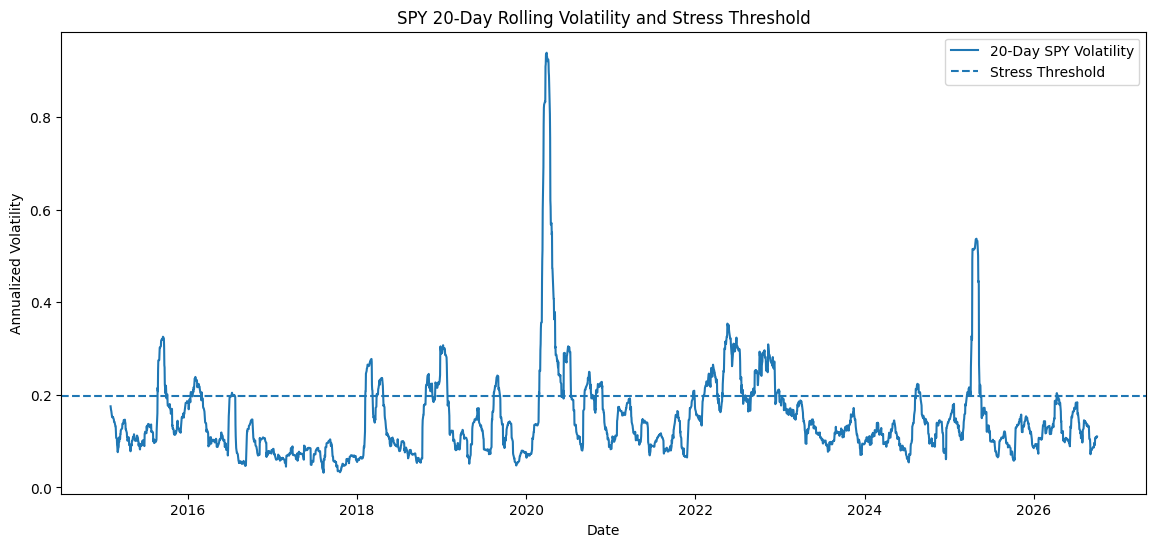

In [20]:
plt.figure(figsize=(14, 6))

plt.plot(
    regimes.index,
    regimes["SPY_Vol_20"],
    label="20-Day SPY Volatility"
)

plt.axhline(
    stress_threshold,
    linestyle="--",
    label="Stress Threshold"
)

plt.title("SPY 20-Day Rolling Volatility and Stress Threshold")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.legend()

plt.show()

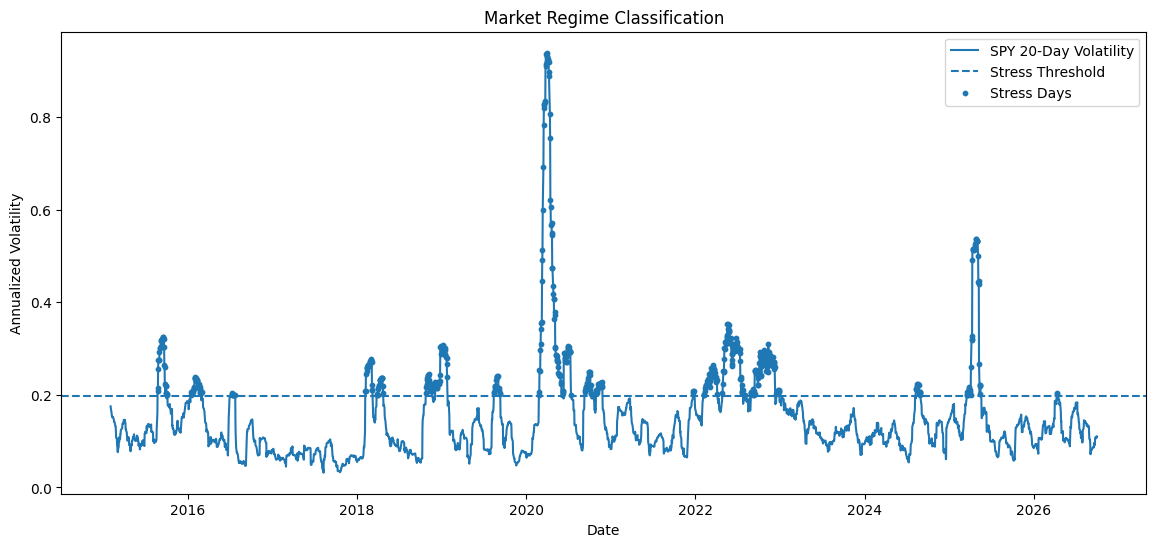

In [21]:
plt.figure(figsize=(14, 6))

plt.plot(
    regimes.index,
    regimes["SPY_Vol_20"],
    label="SPY 20-Day Volatility"
)

plt.axhline(
    stress_threshold,
    linestyle="--",
    label="Stress Threshold"
)

stress_days = regimes[
    regimes["Regime"] == "Stress"
]

plt.scatter(
    stress_days.index,
    stress_days["SPY_Vol_20"],
    s=10,
    label="Stress Days"
)

plt.title("Market Regime Classification")
plt.xlabel("Date")
plt.ylabel("Annualized Volatility")
plt.legend()

plt.show()

In [22]:
returns_with_regime = returns.join(
    regimes["Regime"],
    how="inner"
)

In [23]:
returns_with_regime.head()

,SPY,TLT,GLD,BTC-USD,Regime
2015-02-03,0.014358,-0.021393,-0.011254,-0.047102,Normal
2015-02-04,-0.003816,0.001707,0.004369,-0.001828,Normal
2015-02-05,0.010045,-0.011040,0.001726,-0.043894,Normal
2015-02-06,-0.002769,-0.017861,-0.026205,0.023466,Normal
2015-02-09,-0.004486,-0.001605,0.004457,-0.009747,Normal


In [24]:
normal_returns = returns_with_regime[
    returns_with_regime["Regime"] == "Normal"
].drop(columns="Regime")

In [25]:
normal_returns.head()

,SPY,TLT,GLD,BTC-USD
2015-02-03,0.014358,-0.021393,-0.011254,-0.047102
2015-02-04,-0.003816,0.001707,0.004369,-0.001828
2015-02-05,0.010045,-0.011040,0.001726,-0.043894
2015-02-06,-0.002769,-0.017861,-0.026205,0.023466
2015-02-09,-0.004486,-0.001605,0.004457,-0.009747


In [26]:
stress_returns = returns_with_regime[
    returns_with_regime["Regime"] == "Stress"
].drop(columns="Regime")

In [27]:
stress_returns.head()

,SPY,TLT,GLD,BTC-USD
2015-08-25,-0.011837,-0.016196,-0.012472,0.051453
2015-08-26,0.037675,-0.019492,-0.013744,0.018872
2015-08-27,0.024434,0.000574,0.000557,-0.004714
2015-08-28,0.000050,0.002947,0.008964,0.029057
2015-08-31,-0.008111,-0.007712,0.001103,-0.005808


In [28]:
normal_vol = normal_returns.std() * np.sqrt(252)
stress_vol = stress_returns.std() * np.sqrt(252)

vol_comparison = pd.DataFrame({
    "Normal Volatility": normal_vol,
    "Stress Volatility": stress_vol
})

vol_comparison

,Normal Volatility,Stress Volatility
SPY,0.130275,0.300519
TLT,0.131971,0.200230
GLD,0.159299,0.177476
BTC-USD,0.632536,0.718562


In [29]:
normal_corr = normal_returns.corr()

normal_corr

,SPY,TLT,GLD,BTC-USD
SPY,1.000000,-0.092169,0.083242,0.168581
TLT,-0.092169,1.000000,0.253044,-0.006183
GLD,0.083242,0.253044,1.000000,0.091757
BTC-USD,0.168581,-0.006183,0.091757,1.000000


In [30]:
stress_corr = stress_returns.corr()

stress_corr

,SPY,TLT,GLD,BTC-USD
SPY,1.000000,-0.254710,0.078156,0.406999
TLT,-0.254710,1.000000,0.266299,-0.030309
GLD,0.078156,0.266299,1.000000,0.152733
BTC-USD,0.406999,-0.030309,0.152733,1.000000


In [31]:
correlation_change = stress_corr - normal_corr

correlation_change

,SPY,TLT,GLD,BTC-USD
SPY,0.000000,-0.162541,-0.005086,0.238418
TLT,-0.162541,0.000000,0.013256,-0.024126
GLD,-0.005086,0.013256,0.000000,0.060975
BTC-USD,0.238418,-0.024126,0.060975,0.000000


In [32]:
returns_with_regime.to_csv(
    "data/processed/returns_with_regime.csv"
)

In [33]:
regimes.to_csv(
    "data/processed/market_regimes.csv"
)

In [34]:
regime_summary = pd.DataFrame({
    "Normal": normal_returns.std() * np.sqrt(252),
    "Stress": stress_returns.std() * np.sqrt(252)
})

regime_summary

,Normal,Stress
SPY,0.130275,0.300519
TLT,0.131971,0.200230
GLD,0.159299,0.177476
BTC-USD,0.632536,0.718562


In [35]:
regime_summary.to_csv(
    "outputs/tables/regime_volatility.csv"
)